# Exercise 1: Business cycle correlations

For this exercise, you'll be using macroeconomic data from the folder `data/FRED`.

The monthly files contain the following variables:

| Variable | Description |
|----------|-------------|
| `DATE` | Month of observation. |
| `CPI` | Consumer Price Index (1982–1984 = 100). |
| `UNRATE` | Unemployment rate, in percent. |
| `FEDFUNDS` | Effective federal funds rate, in percent. |
| `REALRATE` | One-year real interest rate, in percent. |
| `LFPART` | Labor force participation rate, in percent. |

## Part 1 — Loading and concatenating data

1. There are seven decade-specific files named `FRED_monthly_YYYY.csv` where
   `YYYY` identifies the decade by its first year (`YYYY` takes on the values
   1950, 1960, ..., 2010). Write a loop that reads in all seven files as
   DataFrames and stores them in a list.

   *Hint:* Recall from the lecture that you should use
   `pd.read_csv(..., parse_dates=['DATE'])` to automatically parse strings
   stored in the `DATE` column as dates.

2. Use
   [`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
   to concatenate these data sets into a single `DataFrame` and set the
   `DATE` column as the index.

### Solution

In [1]:
# Use files in the local data/ directory
DATA_PATH = '../../data/FRED'

# Uncomment this to load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH2-H26/main/data/FRED'

There are many ways to load the seven files we need. One possibility is to loop over
the decades 1950, 1960, ..., 2010, construct the decade-specific file name, and load
the file.

In [2]:
import pandas as pd

data = []

# Loop over decades: 1950, 1960, ....
for year in range(1950, 2011, 10):
    # File name for current decade
    file = f'FRED_monthly_{year}.csv'

    # Join data folder + filename to get path to CSV file
    path = f'{DATA_PATH}/{file}'

    print(f'Loading data from: {path}')

    # Load decade data
    df = pd.read_csv(path, parse_dates=['DATE'])

    # Append to list of DataFrames
    data.append(df)

Loading data from: ../../data/FRED/FRED_monthly_1950.csv
Loading data from: ../../data/FRED/FRED_monthly_1960.csv
Loading data from: ../../data/FRED/FRED_monthly_1970.csv
Loading data from: ../../data/FRED/FRED_monthly_1980.csv
Loading data from: ../../data/FRED/FRED_monthly_1990.csv
Loading data from: ../../data/FRED/FRED_monthly_2000.csv
Loading data from: ../../data/FRED/FRED_monthly_2010.csv


In [3]:
# Concatenate decade data along the row axis
df = pd.concat(data, axis=0)

# Print first 5 observations
df.head(5)

,DATE,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
0,1950-01-01,23.5,6.5,NaN,NaN,58.9
1,1950-02-01,23.6,6.4,NaN,NaN,58.9
2,1950-03-01,23.6,6.3,NaN,NaN,58.8
3,1950-04-01,23.6,5.8,NaN,NaN,59.2
4,1950-05-01,23.8,5.5,NaN,NaN,59.1


In [4]:
# Print last 5 observations
df.tail(5)

,DATE,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
115,2019-08-01,256.0,3.6,2.1,0.6,63.1
116,2019-09-01,256.4,3.5,2.0,0.3,63.2
117,2019-10-01,257.2,3.6,1.8,-0.0,63.3
118,2019-11-01,257.9,3.6,1.6,-0.2,63.3
119,2019-12-01,258.6,3.6,1.6,-0.3,63.3


The index in the concatenated data is not unique, as you can easily verify:

In [5]:
# Selecting the obs with label 0 returns 7 rows!
df.loc[0]

,DATE,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
0,1950-01-01,23.5,6.5,NaN,NaN,58.9
0,1960-01-01,29.4,5.2,4.0,NaN,59.1
0,1970-01-01,37.9,3.9,9.0,NaN,60.4
0,1980-01-01,78.0,6.3,13.8,NaN,64.0
0,1990-01-01,127.5,5.4,8.2,3.8,66.8
0,2000-01-01,169.3,4.0,5.4,2.7,67.3
0,2010-01-01,217.5,9.8,0.1,-0.8,64.8


For this data set, the date provides a natural unique index.

In [6]:
# Set DATE column as index
df = df.set_index('DATE')

<span style="display: none;">SolutionEnd</span>

## Part 2 — Merging GDP

You realize that your data set does not include GDP since this variable is only
reported at a quarterly frequency.
The file contains real GDP, which adjusts for changes in prices.
Load the GDP data from the file `GDP.csv` and merge it with your monthly data
using an _inner join_.

Explain what happens to the number of observations when you merge the monthly
and quarterly data sets.

### Solution

In [7]:
# Path to GDP data
path = f'{DATA_PATH}/GDP.csv'

# Load GDP data
gdp = pd.read_csv(path, parse_dates=['DATE'], index_col='DATE')

gdp.head(5)

,GDP
DATE,
1947-01-01,2182.7
1947-04-01,2176.9
1947-07-01,2172.4
1947-10-01,2206.5
1948-01-01,2239.7


The inner join reduces the number of observations from 840 months to 280 quarters.
It keeps January, April, July, and October observations, matching the quarterly GDP
dates. Changes in the monthly variables therefore compare the first months of
consecutive quarters.

In [8]:
print(f'Monthly observations: {len(df)}')

# Merge the GDP data using an inner join
# The validate parameter can be used to check that the merge is one-to-one
df = df.join(gdp, how='inner', validate='one_to_one')

print(f'Matched observations: {len(df)}')

df.head(5)

Monthly observations: 840
Matched observations: 280


,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART,GDP
DATE,,,,,,
1950-01-01,23.5,6.5,NaN,NaN,58.9,2346.1
1950-04-01,23.6,5.8,NaN,NaN,59.2,2417.7
1950-07-01,24.1,5.0,NaN,NaN,59.1,2511.1
1950-10-01,24.5,4.2,NaN,NaN,59.4,2559.2
1951-01-01,25.4,3.7,NaN,NaN,59.1,2594.0


<span style="display: none;">SolutionEnd</span>

## Part 3 — GDP growth and unemployment

GDP measures how much an economy produces, and `UNRATE` is the unemployment
rate. We want to explore how changes in these two variables are related.

1. Create a _new_ `DataFrame` containing percent changes in GDP and
   percentage-point changes in `UNRATE`. 
   
   - Compute GDP growth with
      [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
      and multiply by 100 to convert to a percentage. 
   
   - Compute changes in unemployment with
      [`diff()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.diff.html).
      For example, an increase in unemployment from 6% to 7% is a change of 1 percentage point.

2. Use
   [`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
   to compute the correlation between GDP growth and changes in
   unemployment. What do the sign and magnitude of the correlation coefficient
   tell you?
   
3. Create a scatter plot with GDP growth on the horizontal axis and the change
   in unemployment on the vertical axis. Each point should represent one
   quarter. Add horizontal and vertical lines at zero.
   Where are the quarters in which GDP falls and unemployment rises?
   Does unemployment always rise when GDP falls?

### Solution

We use percent changes for GDP and percentage-point changes for unemployment.
For example, GDP rising from 100 to 101 is growth of 1%, while unemployment rising
from 6% to 7% is an increase of 1 percentage point.

In [9]:
# Compute GDP growth in percent
df_changes = df[['GDP']].pct_change() * 100

# Add changes in unemployment in percentage points
df_changes['UNRATE'] = df['UNRATE'].diff()

df_changes.head(5)

,GDP,UNRATE
DATE,,
1950-01-01,NaN,NaN
1950-04-01,3.051873,-0.7
1950-07-01,3.863176,-0.8
1950-10-01,1.915495,-0.8
1951-01-01,1.359800,-0.5


The
[`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
method returns the correlation matrix of all pairwise correlations in the DataFrame.
The first row has missing changes because there is no previous observation; it is
excluded from the calculation.

In [10]:
# Compute pairwise correlations between all columns in the DataFrame
df_corr = df_changes.corr()
df_corr

,GDP,UNRATE
GDP,1.000000,-0.564872
UNRATE,-0.564872,1.000000


We select the GDP row and the UNRATE column to obtain the correlation between GDP
growth and changes in unemployment.

In [11]:
# Select the correlation between GDP growth and changes in unemployment
corr = df_corr.loc['GDP', 'UNRATE']
print(f'Correlation between GDP growth and changes in unemployment: {corr:.4f}')

Correlation between GDP growth and changes in unemployment: -0.5649


We can also see the relationship in a scatter plot. Each point represents one
quarter. The zero lines help us distinguish between rising and falling GDP and
between rising and falling unemployment.

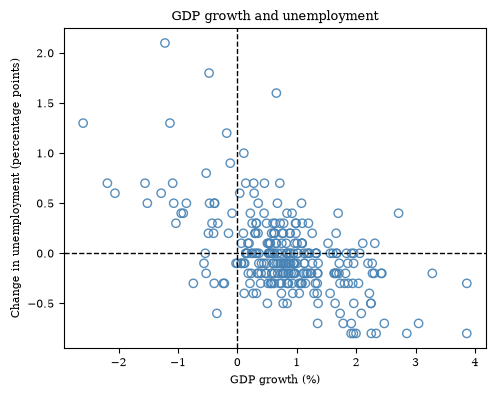

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))

ax.scatter(df_changes['GDP'], df_changes['UNRATE'], alpha=0.9, c='none', ec='steelblue')

# Zero lines separate increases from decreases
ax.axhline(0, color='black', lw=1, ls='--')
ax.axvline(0, color='black', lw=1, ls='--')

ax.set_xlabel('GDP growth (%)')
ax.set_ylabel('Change in unemployment (percentage points)')
ax.set_title('GDP growth and unemployment')

fig.tight_layout()

The correlation is about -0.56, indicating a moderate negative linear relationship:
unemployment tends to rise when GDP growth is lower and fall when GDP growth is
higher. The downward pattern in the scatter plot matches this negative correlation.

Points to the left of the vertical zero line represent quarters in which GDP falls.
Those above the horizontal zero line also have rising unemployment. We can see
points below that line even when GDP falls, so unemployment does not rise in every
quarter in which GDP falls. A correlation describes a tendency, not a rule that
holds for every observation.

<span style="display: none;">SolutionEnd</span>

***
# Exercise 2: Loading many data files

Python can find files matching a pattern using
[`glob.glob()`](https://docs.python.org/3/library/glob.html).

Load the seven decade files `FRED_monthly_YYYY.csv` in the local `data/FRED`
folder using `glob.glob()`. Match names starting with `FRED_monthly_1` or
`FRED_monthly_2`, and store the DataFrames in a list. Parse `DATE` as dates and
set it as the index. Concatenate the list along the row axis and sort by date.

## Solution

In [13]:
# Use files in the local data/ directory
DATA_PATH = '../../data/FRED'

If you are not familiar with more complex patterns used for matching files, one way to solve the problem is as follows:

In [14]:
import glob

import pandas as pd

# List to hold imported DataFrames
data = []

for i in (1, 2):
    # Specify pattern that matches only relevant files
    pattern = f'{DATA_PATH}/FRED_monthly_{i}*.csv'
    # Iterate over files that match the pattern
    for file in glob.glob(pattern):
        print(f'Loading file {file}')
        d = pd.read_csv(file, parse_dates=['DATE'], index_col='DATE')
        data.append(d)

# Concatenate all DataFrames
df = pd.concat(data, axis=0)

# Sort index in case files have been loaded in unexpected order
df = df.sort_index()

Loading file ../../data/FRED/FRED_monthly_1950.csv
Loading file ../../data/FRED/FRED_monthly_1960.csv
Loading file ../../data/FRED/FRED_monthly_1970.csv
Loading file ../../data/FRED/FRED_monthly_1980.csv
Loading file ../../data/FRED/FRED_monthly_1990.csv
Loading file ../../data/FRED/FRED_monthly_2000.csv
Loading file ../../data/FRED/FRED_monthly_2010.csv


However, file matching patterns can be more sophisticated, so you can skip the
outer loop and use the following pattern to match monthly filenames whose year
begins with 1 or 2:

In [15]:
# More sophisticated pattern to match all decades
pattern = f'{DATA_PATH}/FRED_monthly_[12]*.csv'

# List to hold imported DataFrames
data = []

# Iterate over files that match the pattern
for file in glob.glob(pattern):
    print(f'Loading file {file}')
    d = pd.read_csv(file, parse_dates=['DATE'], index_col='DATE')
    data.append(d)

# Concatenate all DataFrames
df = pd.concat(data, axis=0)

# Sort index in case files have been loaded in unexpected order
df = df.sort_index()

Loading file ../../data/FRED/FRED_monthly_1950.csv
Loading file ../../data/FRED/FRED_monthly_1960.csv
Loading file ../../data/FRED/FRED_monthly_1970.csv
Loading file ../../data/FRED/FRED_monthly_1980.csv
Loading file ../../data/FRED/FRED_monthly_1990.csv
Loading file ../../data/FRED/FRED_monthly_2000.csv
Loading file ../../data/FRED/FRED_monthly_2010.csv


<span style="display: none;">SolutionEnd</span>

***
# Exercise 3: Weekly returns of the Magnificent Seven

In this exercise, you are asked to analyze the weekly stock market returns of the
so-called Magnificent Seven, which are some of the most successful tech companies
of the last few decades:
Apple (AAPL), Amazon (AMZN), Alphabet/Google (GOOGL), Meta (META), Microsoft (MSFT), Nvidia (NVDA), and Tesla (TSLA).

The data for this exercise is located in the folder `data/stockmarket/`.
Each stock file contains the following variables:

| Variable | Description |
|----------|-------------|
| `Date` | Trading date. |
| `Open` | Opening stock price for the trading day. |
| `Close` | Closing stock price for the trading day. |

## Part 1 — Loading and computing returns

For each of the seven stocks listed above, there is a corresponding CSV file in
this directory based on the ticker symbol. For example, the file for Apple is `AAPL.csv`.

1. For each ticker symbol, load the corresponding CSV file and make sure that
   the `Date` column is set as the index.

   The DataFrame has two columns, `Open` and `Close`, which contain the
   opening and closing prices for each trading day.

2. Use
   [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
   to resample the daily data to a weekly frequency by specifying
   `resample('W')`, and compute the weekly returns in percent:

   $$
   \text{Weekly returns} =
   \frac{\text{Close price on last day} - \text{Open price on first day}}
        {\text{Open price on first day}} \times 100
   $$

   *Hint:* You can obtain the first and last observations using the
   [`first()`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.Resampler.first.html)
   and
   [`last()`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.Resampler.last.html)
   methods.

3. Append these returns to a list so you can merge them into a single DataFrame
   later.

### Solution

In [16]:
# Use files in the local data/ directory
DATA_PATH = '../../data/stockmarket'

# Uncomment this to load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH2-H26/main/data/stockmarket'

In [17]:
import pandas as pd

# List of ticker symbols for the 7 stocks
symbols = ['AAPL', 'AMZN', 'GOOGL', 'META', 'MSFT', 'NVDA', 'TSLA']

# List to store weekly returns
returns = []

for symbol in symbols:
    # Load this file and use Date as the row index
    filename = f'{DATA_PATH}/{symbol}.csv'
    df = pd.read_csv(filename, parse_dates=['Date'], index_col='Date')

    # Resample to weekly frequency, store first and last prices
    first = df.resample('W')['Open'].first()
    last = df.resample('W')['Close'].last()

    # Compute weekly percentage returns
    ret = (last - first) / first * 100.0

    # Give series the corresponding ticker symbol as name
    ret.name = symbol

    returns.append(ret)

<span style="display: none;">SolutionEnd</span>

## Part 2 — Merging weekly returns

Merge the weekly returns into a single DataFrame, keeping the intersection of
dates available for all 7 stocks. Discard the first and last week of the merged
DataFrame, since the data do not cover a full trading week for every stock.

*Hint:* This can be achieved using either
[`pd.concat(..., join='inner')`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html),
[`pd.merge()`](https://pandas.pydata.org/docs/reference/api/pandas.merge.html),
or
[`DataFrame.join()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html).

### Solution

We use
[`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
with `join='inner'` to keep common weeks. META has only its first trading day in the
first common week, and the last week ends before trading is complete. We drop these
two boundary weeks.

In [18]:
df_returns = pd.concat(returns, axis=1, keys=symbols, join='inner')

# Exclude the first and last common weeks, which are partial weeks
df_returns = df_returns.iloc[1:-1]

Alternatively,
[`join()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html)
can combine a list of Series by their date indexes:

In [19]:
# Join the named Series on their date indexes
df_returns2 = returns[0].to_frame().join(returns[1:], how='inner')

# Exclude the same partial weeks
df_returns2 = df_returns2.iloc[1:-1]

The following code verifies that both methods are equivalent:

In [20]:
df_returns.equals(df_returns2)

True

<span style="display: none;">SolutionEnd</span>

## Part 3 — Pairwise correlations

Finally, you are interested in how the weekly returns are correlated across the
7 stocks.

1. Compute and report the pairwise correlations using
   [`DataFrame.corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).

2. Create a figure with a 7-by-7 grid of subplots showing the pairwise scatter
   plots of weekly returns for each combination of stocks.

   You can do this either with the
   [`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)
   function contained in `pandas.plotting`, or manually build the figure using
   Matplotlib functions.

3. **[Advanced]** Add the corresponding correlation coefficient to each
   off-diagonal subplot (e.g., about 0.43 for AAPL and AMZN).

### Solution

The pairwise correlation matrix can be computed using the 
[`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
method:

In [21]:
# Compute pairwise correlations
corr = df_returns.corr()

# Tabulate correlations
corr

,AAPL,AMZN,GOOGL,META,MSFT,NVDA,TSLA
AAPL,1.000000,0.434348,0.469323,0.312561,0.484202,0.465762,0.348667
AMZN,0.434348,1.000000,0.574210,0.400305,0.540829,0.481812,0.346498
GOOGL,0.469323,0.574210,1.000000,0.426728,0.570538,0.440033,0.335856
META,0.312561,0.400305,0.426728,1.000000,0.410019,0.351740,0.239073
MSFT,0.484202,0.540829,0.570538,0.410019,1.000000,0.552229,0.343546
NVDA,0.465762,0.481812,0.440033,0.351740,0.552229,1.000000,0.372918
TSLA,0.348667,0.346498,0.335856,0.239073,0.343546,0.372918,1.000000


The Pearson correlation coefficient lies in $[-1, 1]$. Its sign indicates the
direction of the linear association, and its magnitude indicates the strength.
Values near zero indicate little linear association; nonlinear relationships may
still exist.

The simplest way to create the pairwise scatter plots is to use
[`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)
from the `pandas.plotting` module, as this does all the work for us:

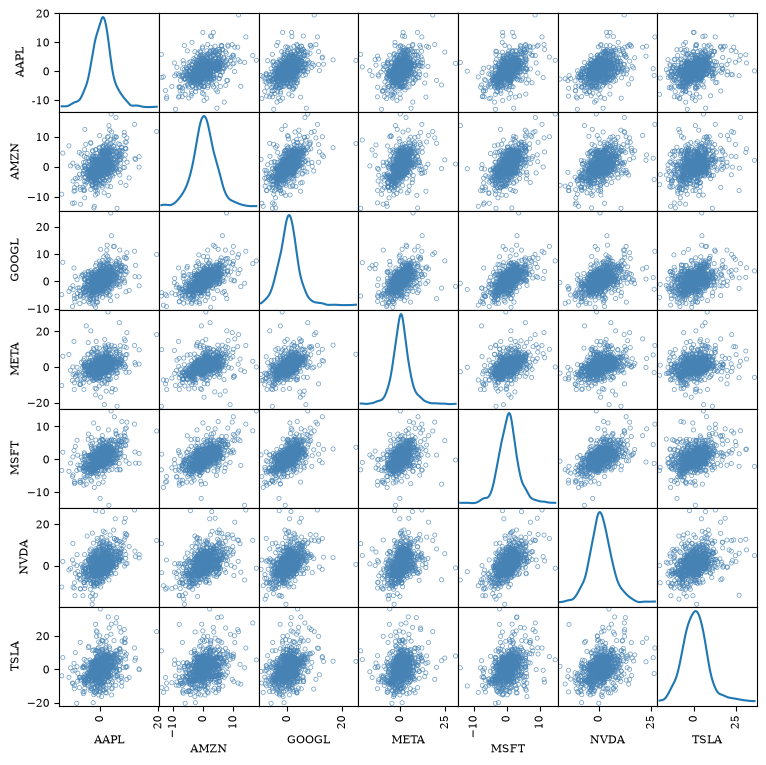

In [22]:
from pandas.plotting import scatter_matrix

# Create figure with 7x7 scatter plots. Main diagonal shows kernel density
# for each stock.
axes = scatter_matrix(
    df_returns,
    figsize=(9, 9),
    alpha=0.8,  # Set transparency of markers
    color='none',  # Color of markers (no filling)
    edgecolors='steelblue',  # Color of marker edges
    lw=0.5,  # Width of marker edges
    diagonal='kde',  # Add kernel density estimate to diagonal
)

Alternatively, create the scatter plots manually and add the correlations as text.
The diagonal panels below show ticker symbols instead of density estimates.

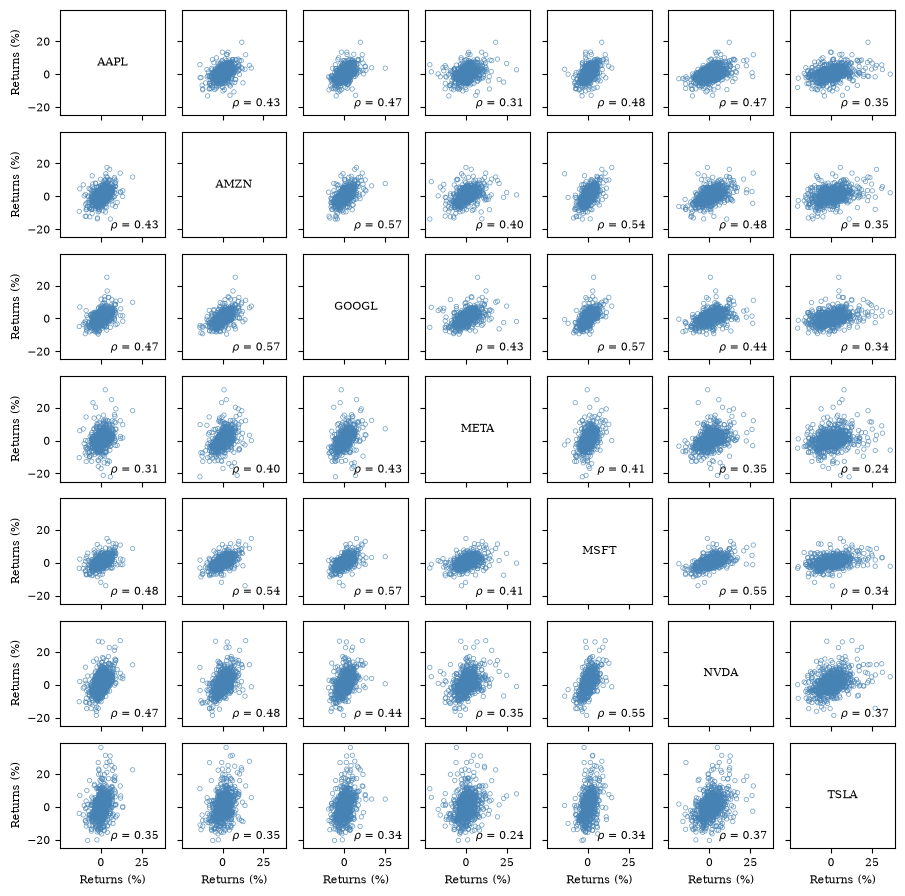

In [23]:
import matplotlib.pyplot as plt

# List of tickers present in DataFrame
tickers = df_returns.columns.to_list()

n = len(tickers)

fig, axes = plt.subplots(n, n, figsize=(9, 9), sharex=True, sharey=True)

# Iterate over rows and columns
for i in range(n):
    for j in range(n):
        # Select current axes
        ax = axes[i, j]

        # Add axis labels to the last row and first column
        if i == n - 1:
            ax.set_xlabel('Returns (%)')
        if j == 0:
            ax.set_ylabel('Returns (%)')

        # For diagonal panels, print the ticker symbol instead of
        # (exactly diagonal) scatter plot.
        if i == j:
            ax.text(
                0.5, 0.5, tickers[i], transform=ax.transAxes, va='center', ha='center'
            )
            continue

        # Get x- and y-values for this panel
        xvalues = df_returns.iloc[:, j]
        yvalues = df_returns.iloc[:, i]

        # Create scatter plot
        ax.scatter(
            xvalues,
            yvalues,
            s=10,
            alpha=0.8,
            lw=0.5,
            color='none',
            edgecolors='steelblue',
        )

        # Add text with pairwise correlation
        ax.text(
            0.95,
            0.05,
            rf'$\rho$ = {corr.iloc[i, j]:.2f}',
            transform=ax.transAxes,
            va='bottom',
            ha='right',
        )


fig.tight_layout()

<span style="display: none;">SolutionEnd</span>

***
# Exercise 4: Inflation expectations and past inflation

In this exercise, we explore whether people's expectations about future inflation
are related to inflation they have recently experienced. Inflation measures how
much prices rise, while deflation means that prices fall.

We use a 10% sample of
[Survey of Consumer Expectations (SCE)](https://www.newyorkfed.org/microeconomics/sce),
a survey of US consumers administered by the Federal Reserve Bank of New York.
The files in `data/SCE_10pct/` contain individual responses from June 2013 through
September 2025. Missing values and extreme forecasts have already been removed.
Each row represents one respondent in one survey month.

| Variable | Description |
|----------|-------------|
| `userid` | Respondent identifier. |
| `date` | First day of the survey month. |
| `female` | Gender indicator: 0 = male, 1 = female. |
| `infl_1y` | Expected inflation over the next 12 months, in percent. |

For example, `infl_1y = 3.5` means that the respondent expects prices to rise by
3.5% over the next 12 months. A negative value indicates expected deflation.

## Part 1 — Loading and grouping

1. Write a loop to load the 13 annual files `SCE_2013.csv`, ..., `SCE_2025.csv`
   into a list of DataFrames. Parse `date` as a date column.

   *Hint:* Use `pd.read_csv(..., parse_dates=['date'])` to automatically parse strings stored in the `date` column as dates.

2. Concatenate these DataFrames into a single DataFrame using 
   [`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
   and sort the rows by `date` and `userid`.

3. Group by `date` and `female` to calculate mean expected inflation for each
   month and gender. Keep the result as a DataFrame, rename `infl_1y` to
   `expected`, and use `reset_index()` to make the grouping variables regular
   columns again.

   *Hint:* Use
   [`rename()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rename.html)
   to rename columns.

### Solution

In [24]:
# Use files in the local data/ directory
DATA_PATH = '../../data'

# Uncomment this to load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH2-H26/main/data'

We load the annual files in a loop, just as we loaded decade-specific files in
Exercise 1. Parsing `date` as dates lets us match the survey months to CPI later.

In [25]:
import pandas as pd

data = []
# Loop over years 2013 through 2025 (inclusive)
for year in range(2013, 2026):
    # File name for current year
    file = f'{DATA_PATH}/SCE_10pct/SCE_{year}.csv'
    df_year = pd.read_csv(file, parse_dates=['date'])
    data.append(df_year)

Alternatively, we can use `glob.glob()` to find the local annual files, as in
Exercise 2. The pattern `SCE_*.csv` matches all annual SCE files in this folder.
Both approaches create a list named `data`, which we concatenate below.

In [26]:
import glob

# Find annual SCE files in the local data folder
pattern = f'{DATA_PATH}/SCE_10pct/SCE_*.csv'

data = []
for file in glob.glob(pattern):
    df_year = pd.read_csv(file, parse_dates=['date'])
    data.append(df_year)

In [27]:
# Combine all annual files
df_sce = pd.concat(data, ignore_index=True)

# Sort by survey month and respondent ID, creating a new row index
df_sce = df_sce.sort_values(['date', 'userid'], ignore_index=True)

df_sce.head()

,userid,date,female,infl_1y
0,70003252,2013-06-01,0,4.0
1,70006353,2013-06-01,1,3.0
2,70009175,2013-06-01,1,5.0
3,70009180,2013-06-01,1,2.0
4,70009469,2013-06-01,0,3.0


We group by both `date` and `female`. This gives us two averages per month: one
for men and one for women. Selecting `[['infl_1y']]` keeps the result as a
DataFrame. We use `reset_index()` to move the grouping variables back into
columns for the merge and plot.

In [28]:
# Calculate mean expected inflation for each month and gender
df_expect = df_sce.groupby(['date', 'female'])[['infl_1y']].mean()
df_expect = df_expect.rename(columns={'infl_1y': 'expected'})
df_expect = df_expect.reset_index()

df_expect.head()

,date,female,expected
0,2013-06-01,0,4.458333
1,2013-06-01,1,7.913462
2,2013-07-01,0,5.420290
3,2013-07-01,1,5.000000
4,2013-08-01,0,4.840404


<span style="display: none;">SolutionEnd</span>

## Part 2 — Past inflation and merging

The Consumer Price Index (CPI) measures the overall level of consumer prices.
For example, if the CPI rises from 100 to 104 over 12 months, inflation over that
period is 4%.

1. Load `data/FRED/CPI.csv`, parse `DATE` as dates, and rename it to `date`.
2. Compute inflation over the preceding 12 months and store it in a new column
   named `past_inflation`:
   $$
   \text{Past inflation}_t =
   \left(\frac{CPI_t}{CPI_{t-12}} - 1\right) \times 100.
   $$
   Here, $t$ is the current month and $t-12$ is the same month one year earlier.

   *Hint:* Use `pct_change(periods=12)` and multiply by 100. Compute this change
   on the monthly CPI data before merging.
3. Use `pd.merge()` to merge `past_inflation` with the monthly expectations
   from Part 1, matching on the `date` column. Keep both genders for
   every survey month. Why do men and women receive the same observed inflation
   rate in each month?

### Solution

In [29]:
# Load CPI levels with a monthly date column
file = f'{DATA_PATH}/FRED/CPI.csv'
df_cpi = pd.read_csv(file, parse_dates=['DATE'])

# Use the same date column name as in the survey data
df_cpi = df_cpi.rename(columns={'DATE': 'date'})

We compare each month's CPI with the CPI 12 months earlier.
We calculate this change before merging the datasets: the CPI data have one row
per month, while the grouped survey data have two. The first 12 CPI observations
have missing changes because we do not observe the preceding year's CPI for
those months. These dates are well before the survey starts.

In [30]:
# Calculate inflation over the preceding 12 months, in percent
df_cpi['past_inflation'] = df_cpi['CPI'].pct_change(periods=12) * 100

We use `pd.merge()` to match the `date` columns in the two DataFrames.
The left join keeps all monthly expectations. This is a many-to-one merge:
the two gender groups match the same CPI observation, so each CPI date must
be unique.

In [31]:
# Match each monthly gender average to observed inflation in that month
df_infl = pd.merge(df_expect, df_cpi[['date', 'past_inflation']], on='date', how='left')

df_infl.head()

,date,female,expected,past_inflation
0,2013-06-01,0,4.458333,1.706783
1,2013-06-01,1,7.913462,1.706783
2,2013-07-01,0,5.420290,1.881015
3,2013-07-01,1,5.000000,1.881015
4,2013-08-01,0,4.840404,1.565898


<span style="display: none;">SolutionEnd</span>

## Part 3 — Plotting and interpretation

1. Create a figure with two scatter plots, one for men and one for women.
   Put observed inflation over the *past* 12 months on the horizontal axis
   and mean expected inflation over the *next* 12 months on the vertical axis.
   Each point should represent one month.

   Add axis labels and panel titles. Use the same axis limits in both panels so
   that we can compare the groups.

2. Are higher past inflation rates associated with higher inflation expectations?
   Does the relationship differ by gender?

### Solution

We select each gender's monthly observations and plot them in a separate panel.
Using `sharex=True` and `sharey=True` gives both panels the same axis limits.
Each point pairs a group's average forecast for the coming year with inflation
over the year preceding that survey month.

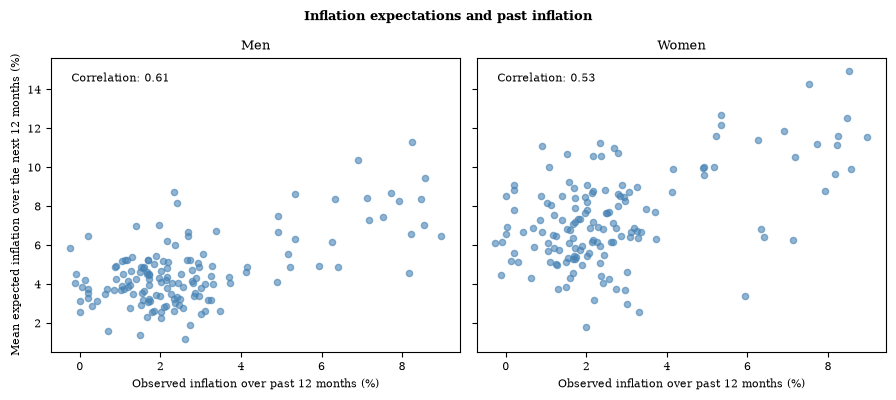

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
labels = ['Men', 'Women']

for female, ax in enumerate(axes):
    # Select the monthly averages for this gender
    df_gender = df_infl.loc[df_infl['female'] == female]

    ax.scatter(
        df_gender['past_inflation'],
        df_gender['expected'],
        s=20,
        alpha=0.6,
        color='steelblue',
    )
    corr = df_gender['past_inflation'].corr(df_gender['expected'])

    # Axes coordinates run from 0 to 1 across each panel
    ax.text(0.05, 0.95, f'Correlation: {corr:.2f}', transform=ax.transAxes, va='top')

    ax.set_xlabel('Observed inflation over past 12 months (%)')
    ax.set_title(labels[female])

axes[0].set_ylabel('Mean expected inflation over the next 12 months (%)')
fig.suptitle('Inflation expectations and past inflation', fontweight='bold')
fig.tight_layout()

In both panels, we see a positive association: months with higher past inflation
tend to have higher average inflation expectations. The points also show
considerable scatter, so the relationship is not exact.

The association is stronger for men (0.61) than for women (0.53), while women
generally have higher mean inflation expectations.

<span style="display: none;">SolutionEnd</span>